In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

##### La strategie ce base sur le papers dans le folder, l'idée c'est de venir mettre en place donc une strategie baser sur le momentum mais ici la détermination de la trend et de la taille de la possition devrat etre déterminer par un model de deep learning


Equation de la strategie

$$
r^{port}_{t,t+1}=\frac{1}{N_t}\sum_{i=1}^{N_t} X_t^{(i)}\frac{\sigma_{tgt}}{\sigma_t^{(i)}}\ r_{t,t+1}^{(i)}
$$

- $r_{t,t+1}^{(i)}$ : le rendement de l'actif i entre aujourd'hui et demain. 
- $\sigma_t^{(i)}$ : la volatilité de l'actif i, connue aujourd'hui. 
- $X_t^{(i)}$ : la position décidée aujourd'hui, entre -1 et 1.
- $\sigma_tgt$ = 15% : la volatilité visée.
- $N_t$ : le nombre d'actifs disponible ce jour-là.

##### 

In [20]:
# import data
DATA_DIR = Path(r"C:\Users\Jordi\Desktop\Trading\quant_lab\data\raw")
PROCESSED_DIR = DATA_DIR.parent / "processed"

GARDER = [
    "AN", "AX", "BN", "CA", "CB", "CC", "CN", "CT", "DA", "DT", "DX", "EN",
    "ER", "ES", "FB", "FN", "GI", "HS", "JN", "JO", "KC", "KW", "MP", "MW",
    "NK", "SB", "SN", "TU", "TY", "UB", "UZ", "XU", "YM", "ZA", "ZC", "ZF",
    "ZG", "ZL", "ZM", "ZN", "ZO", "ZP", "ZR", "ZS", "ZT", "ZW", "ZZ",
]

actifs = {}
for x in PROCESSED_DIR.glob("*.csv"):
    if x.stem not in GARDER:
        continue
    actifs[x.stem] = pd.read_csv(x, index_col="date", parse_dates=True)

data = pd.concat(actifs, axis=1, sort=True)
print(len(actifs), "actifs chargés |", data.shape)

47 actifs chargés | (14827, 94)


In [22]:
# Calcul de la volat 
volat = data.xs("rendement", axis=1, level=1).ewm(span=60, min_periods=60).std() * np.sqrt(252)
rendements = data.xs("rendement", axis=1, level=1)

rendement annuel       0.037
volatilité annuelle    0.049
sharpe                 0.743
drawdown max           0.159
dtype: float64


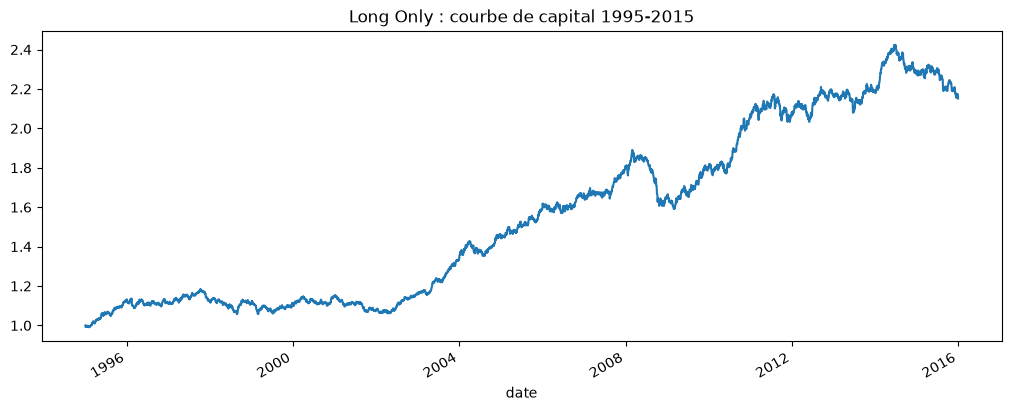

In [26]:
# Rendements de chaque actif (dates x actifs)
SIGMA_TGT = 0.15


def backtest(X):
    """Équation 1 : rendement quotidien du portefeuille pour une table de positions X."""
    rendement_demain = rendements.shift(-1)       # la position du jour t gagne le rendement de t+1
    contributions = X * (SIGMA_TGT / volat) * rendement_demain
    return contributions.mean(axis=1)             # moyenne sur les actifs disponibles = 1/N_t x somme


def resultats(r):
    """Métriques du paper sur 1995-2015."""
    r = r.loc["1995":"2015"].dropna()
    capital = (1 + r).cumprod()
    drawdown = capital / capital.cummax() - 1
    return pd.Series({
        "rendement annuel": r.mean() * 252,
        "volatilité annuelle": r.std() * np.sqrt(252),
        "sharpe": r.mean() / r.std() * np.sqrt(252),
        "drawdown max": -drawdown.min(),
    })


# Stratégie 1 : Long Only (X = 1 partout où la volatilité existe)
X_long = pd.DataFrame(1.0, index=volat.index, columns=volat.columns).where(volat.notna())
r_long = backtest(X_long)

print(resultats(r_long).round(3))

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
(1 + r_long.loc["1995":"2015"].dropna()).cumprod().plot(ax=ax)
ax.set_title("Long Only : courbe de capital 1995-2015")
plt.show()